# 作业 02：用 PyTorch 训练 CIFAR-10 分类器

先按 [README](README.md) 安装依赖，选择 **Python (cv_gpu)** 内核，再从上到下运行。首次运行会下载数据。

本题用同一个卷积神经网络（CNN），先在 GPU 上训练，再在 CPU 上从同一份初始权重重新训练。最后比较两次实验的损失、准确率和训练耗时。

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib import font_manager
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# 为图表选用系统中可用的中文字体。
chinese_fonts = ["Microsoft YaHei", "SimHei", "PingFang SC", "Noto Sans CJK SC", "Arial Unicode MS"]
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams["font.sans-serif"] = [
    font for font in chinese_fonts if font in available_fonts
] + ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
EPOCHS = 6
BATCH_SIZE = 128
LEARNING_RATE = 0.001

assert torch.cuda.is_available(), "CUDA 不可用，请先完成作业 01，并检查是否选了 cv_gpu 内核。"
gpu = torch.device("cuda:0")
cpu = torch.device("cpu")
print(f"GPU：{torch.cuda.get_device_name(gpu)}")
print(f"PyTorch 使用的 CPU 线程数：{torch.get_num_threads()}")

GPU：NVIDIA GeForce RTX 5060
PyTorch 使用的 CPU 线程数：10


## 1. 下载并划分数据

CIFAR-10 有 60,000 张 32×32 的 RGB 图片，共 10 类。用 `torchvision.datasets.CIFAR10` 加载官方数据。第一次下载后会在 `data/` 中复用缓存。

| 数据集 | 图片数量 | 用途 |
| --- | ---: | --- |
| 训练集 | 45,000 | 更新模型参数 |
| 验证集 | 5,000 | 每轮检查表现，按准确率选择最佳轮次 |
| 测试集 | 10,000 | 两次训练结束、选好最佳轮次后再评估 |

用固定随机种子从官方训练集划出验证集，官方测试集保留原样。预处理把像素转换为张量，再把数值从 `[0, 1]` 缩放到 `[-1, 1]`。

[CIFAR-10 数据说明](https://www.cs.toronto.edu/~kriz/cifar.html) · [TorchVision CIFAR10 文档](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html)

In [2]:
data_dir = Path("data")
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])
full_train = datasets.CIFAR10(data_dir, train=True, download=True, transform=preprocess)
train_set, val_set = random_split(
    full_train, [45_000, 5_000], generator=torch.Generator().manual_seed(SEED)
)
test_set = datasets.CIFAR10(data_dir, train=False, download=True, transform=preprocess)

print(f"训练集：{len(train_set):,} 张")
print(f"验证集：{len(val_set):,} 张")
print(f"测试集：{len(test_set):,} 张")
print("类别：", "、".join(full_train.classes))
image, label = train_set[0]
print(f"单张图像形状：{tuple(image.shape)}，标签：{full_train.classes[label]}")

训练集：45,000 张
验证集：5,000 张
测试集：10,000 张
类别： airplane、automobile、bird、cat、deer、dog、frog、horse、ship、truck
单张图像形状：(3, 32, 32)，标签：frog


## 2. 定义分类器

三层卷积提取图像特征。每个卷积块依次执行卷积、ReLU 和最大池化，图像宽高从 32 逐步降到 4。最后将特征展开，输出 10 个类别分数。交叉熵直接使用这些分数和整数标签。

In [3]:
def make_model():
    return nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 10),
    )

torch.manual_seed(SEED)
initial_weights = make_model().state_dict()
print(f"模型参数：{sum(t.numel() for t in initial_weights.values()):,} 个")

模型参数：33,834 个


## 3. 编写共用的训练和评估代码

每批训练依次完成前向计算、计算损失、反向传播和更新参数。评估时关闭梯度计算。每轮的损失按样本数取平均，准确率是预测正确的样本占比。

GPU 和 CPU 共用相同的初始权重、数据顺序、批大小、学习率和轮数。计时包含训练批次的读取、数据搬运和参数更新，从第一轮开始累计。下载、验证和测试在计时之外。CUDA 运算可能异步执行，所以在计时开始和结束时都同步 GPU。

In [4]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)
    sample_count = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)

            scores = model(images)
            loss = criterion(scores, labels)
            if training:
                loss.backward()
                optimizer.step()

            loss_sum += loss.detach() * labels.size(0)
            correct += (scores.detach().argmax(dim=1) == labels).sum()
            sample_count += labels.size(0)

    return loss_sum.item() / sample_count, correct.item() / sample_count

def train_model(device):
    # 每次新建优化器，并用相同种子生成训练批次顺序。
    train_loader = DataLoader(
        train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )
    val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=0)
    model = make_model()
    model.load_state_dict(initial_weights)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history, checkpoints = [], []

    for epoch in range(1, EPOCHS + 1):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        start = perf_counter()
        train_loss, train_acc = run_epoch(model, train_loader, device, optimizer)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        train_seconds = perf_counter() - start

        val_loss, val_acc = run_epoch(model, val_loader, device)
        history.append(dict(
            train_loss=train_loss, train_acc=train_acc,
            val_loss=val_loss, val_acc=val_acc, train_seconds=train_seconds,
        ))
        checkpoints.append({
            name: tensor.detach().to("cpu", copy=True)
            for name, tensor in model.state_dict().items()
        })
        print(
            f"{device} 第 {epoch}/{EPOCHS} 轮 | "
            f"训练损失 {train_loss:.3f}，准确率 {train_acc:.1%} | "
            f"验证损失 {val_loss:.3f}，准确率 {val_acc:.1%} | "
            f"训练耗时 {train_seconds:.2f} 秒",
            flush=True,
        )

    return history, checkpoints

## 4. 先用 GPU 训练，再用 CPU 训练

运行下一格，在输出中查看每轮指标。CPU 运行时间取决于电脑配置，请等两次训练都结束再继续。

In [5]:
print("开始 GPU 训练")
gpu_history, gpu_checkpoints = train_model(gpu)

print("\n开始 CPU 训练")
cpu_history, cpu_checkpoints = train_model(cpu)

开始 GPU 训练
cuda:0 第 1/6 轮 | 训练损失 1.587，准确率 42.7% | 验证损失 1.376，准确率 50.1% | 训练耗时 12.41 秒
cuda:0 第 2/6 轮 | 训练损失 1.253，准确率 55.7% | 验证损失 1.156，准确率 59.1% | 训练耗时 11.85 秒
cuda:0 第 3/6 轮 | 训练损失 1.104，准确率 61.0% | 验证损失 1.074，准确率 61.8% | 训练耗时 11.71 秒
cuda:0 第 4/6 轮 | 训练损失 1.003，准确率 64.9% | 验证损失 1.019，准确率 63.7% | 训练耗时 11.66 秒
cuda:0 第 5/6 轮 | 训练损失 0.932，准确率 67.6% | 验证损失 0.940，准确率 67.5% | 训练耗时 11.66 秒
cuda:0 第 6/6 轮 | 训练损失 0.875，准确率 69.7% | 验证损失 0.910，准确率 68.3% | 训练耗时 11.94 秒

开始 CPU 训练
cpu 第 1/6 轮 | 训练损失 1.588，准确率 42.7% | 验证损失 1.379，准确率 49.9% | 训练耗时 29.92 秒
cpu 第 2/6 轮 | 训练损失 1.258，准确率 55.4% | 验证损失 1.168，准确率 59.1% | 训练耗时 30.26 秒
cpu 第 3/6 轮 | 训练损失 1.109，准确率 60.9% | 验证损失 1.078，准确率 61.8% | 训练耗时 30.13 秒
cpu 第 4/6 轮 | 训练损失 1.007，准确率 64.7% | 验证损失 1.021，准确率 63.7% | 训练耗时 30.33 秒
cpu 第 5/6 轮 | 训练损失 0.935，准确率 67.5% | 验证损失 0.947，准确率 67.2% | 训练耗时 30.23 秒
cpu 第 6/6 轮 | 训练损失 0.878，准确率 69.4% | 验证损失 0.931，准确率 67.0% | 训练耗时 30.24 秒


## 5. 先选模型，再看测试结果

对每台设备，选择验证准确率最高的一轮，同分时选较早的一轮。确定后，再用测试集回看各轮保存的模型，画出测试曲线。提交时报告按验证集选出的模型的测试成绩。

In [6]:
runs = {
    "GPU": (gpu, gpu_history, gpu_checkpoints),
    "CPU": (cpu, cpu_history, cpu_checkpoints),
}
best_indices = {
    name: max(range(len(history)), key=lambda i: history[i]["val_acc"])
    for name, (_, history, _) in runs.items()
}
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=0)

for name, (device, history, checkpoints) in runs.items():
    model = make_model().to(device)
    for row, weights in zip(history, checkpoints):
        model.load_state_dict(weights)
        row["test_loss"], row["test_acc"] = run_epoch(model, test_loader, device)

    best = best_indices[name]
    row = history[best]
    print(
        f"{name}：验证集选中第 {best + 1} 轮，"
        f"验证准确率 {row['val_acc']:.1%}，"
        f"测试损失 {row['test_loss']:.3f}，测试准确率 {row['test_acc']:.1%}"
    )

GPU：验证集选中第 6 轮，验证准确率 68.3%，测试损失 0.923，测试准确率 67.4%
CPU：验证集选中第 5 轮，验证准确率 67.2%，测试损失 0.960，测试准确率 66.7%


## 6. 绘制损失和准确率曲线

每行对应一种设备，竖线标出验证集选出的轮次。观察训练、验证和测试曲线是否一起改善。

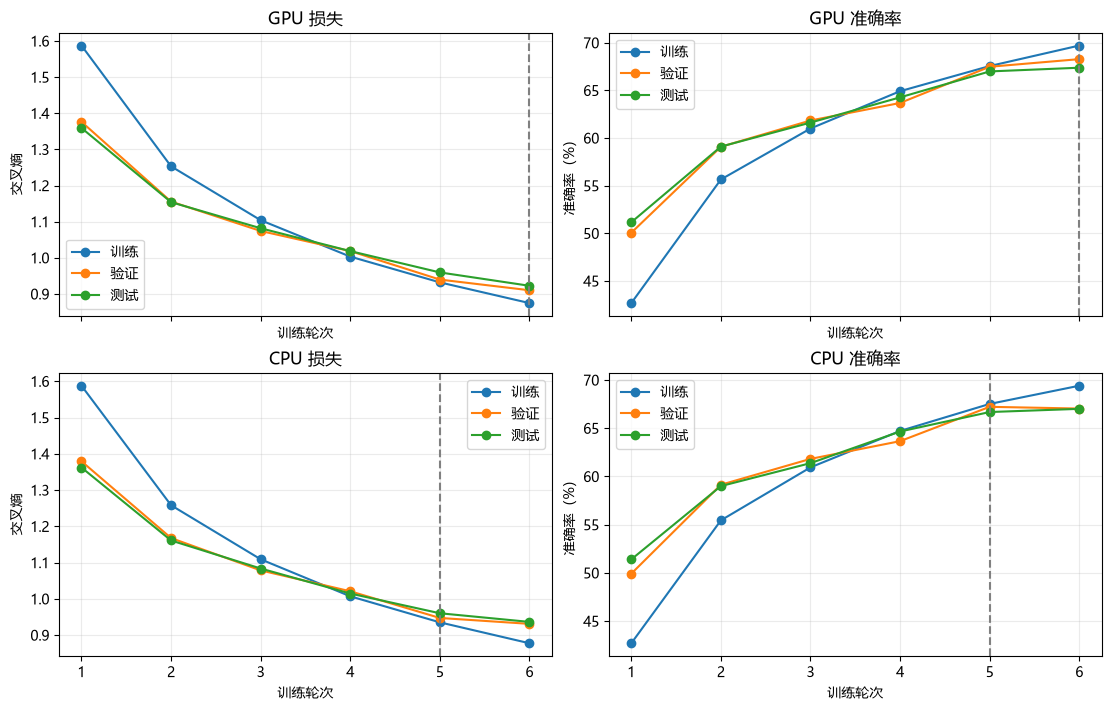

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout="constrained")
epochs = range(1, EPOCHS + 1)

for (name, (_, history, _)), (loss_ax, acc_ax) in zip(runs.items(), axes):
    for key, label in [("train", "训练"), ("val", "验证"), ("test", "测试")]:
        loss_ax.plot(epochs, [row[f"{key}_loss"] for row in history], "o-", label=label)
        acc_ax.plot(epochs, [row[f"{key}_acc"] * 100 for row in history], "o-", label=label)
    loss_ax.set(title=f"{name} 损失", ylabel="交叉熵")
    acc_ax.set(title=f"{name} 准确率", ylabel="准确率（%）")
    for ax in (loss_ax, acc_ax):
        ax.axvline(best_indices[name] + 1, color="gray", linestyle="--")
        ax.set(xticks=list(epochs), xlabel="训练轮次")
        ax.grid(alpha=0.25)
        ax.legend()

plt.show()

## 7. 比较训练耗时

把每轮的训练耗时相加，计算加速倍数 `CPU 耗时 ÷ GPU 耗时`。大于 1 表示这次实验中 GPU 更快。

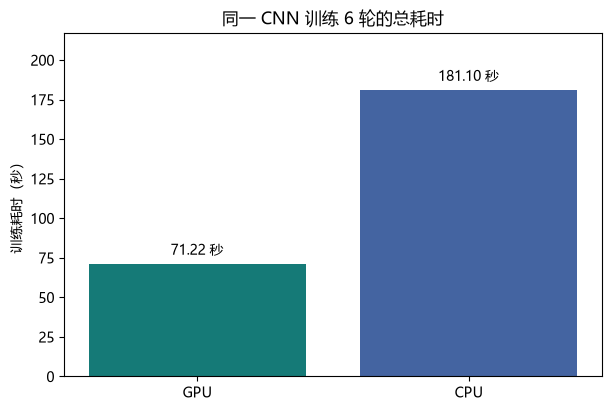

CPU 耗时 ÷ GPU 耗时 = 2.54 倍


In [8]:
totals = {
    name: sum(row["train_seconds"] for row in history)
    for name, (_, history, _) in runs.items()
}
speedup = totals["CPU"] / totals["GPU"]

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
bars = ax.bar(list(totals), list(totals.values()), color=["#157A77", "#4464A1"])
ax.bar_label(bars, labels=[f"{seconds:.2f} 秒" for seconds in totals.values()], padding=4)
ax.set(title=f"同一 CNN 训练 {EPOCHS} 轮的总耗时", ylabel="训练耗时（秒）")
ax.set_ylim(0, max(totals.values()) * 1.2)
plt.show()

print(f"CPU 耗时 ÷ GPU 耗时 = {speedup:.2f} 倍")

## 提交前填写（50分）

1. GPU 和 CPU 各训练了多少秒？GPU六轮约71秒，CPU六轮约181秒。加速倍数是多少？约2.54倍（20分）
2. 两次实验分别选中了哪一轮？GPU第六轮，CPU第五轮。对应的测试准确率是多少？GPU 67.4%,CPU 66.7%（10分）
3. 比较训练和验证曲线。它们在最后两轮的变化有何不同？训练损失最后两轮明显下降，训练准确率持续上升,验证损失下降放缓,验证准确率几乎不动,训练损失明显低于验证损失（20分）

**回答：**

保存并提交带运行输出、图表和回答的 Notebook。